##Системы искусственного интеллекта

##ЛР4. Decision Tree
[10 баллов]

## О формате сдачи (все ЛР)

🔷 **<font color='plum'>При решении используйте данный шаблон</font>**

    ✅ Можно добавлять новые ячейки любых типов
    ❌ Не нужно удалять текстовые ячейки c разметкой частей ноутбука и формулировками заданий


🔷 **<font color='plum'>При оценивании задач учитывается код</font>**

    ✅ Задания, в которых необходим код, могут помечаться фразами "Your code here"/"Ваш код" и аналогичными
    ❌ Ответы на вопросы без сопутствующего кода оцениваются в 0 баллов
    ❌ Наличие работоспособного кода в ноутбуке, если на сказано иного, обязательно

🔷 **<font color='plum'>При оценивании задач учитываются выводы</font>**

    ✅ Задания, в которых необходимы выводы, могут помечаться фразами "Вывод"/"Ответ на вопрос"/"Ваш текст" и аналогичными
    ✅ Выводы подразумевают текстовый (письменный, не устный) ответ (можно писать markdown, latex).
    ✅ Сопутствующие изображения, графики, таблички - приветствуются!
    ❌ При отсутствии выводов задание не засчитается на полный балл

🔷 **<font color='plum'>Устная защита</font>**

    ❌❌❌ Если не пройдена устная защита по ЛР, то баллы не начисляются вовсе
    (вопросы устной защиты охватывают лекционный материал и практический материал по заданиям ЛР, список вопросов не публикуется)

## Этапы

Задание состоит в детальном изучении данных и построении модели предсказания стоимости объекта недвижимости.

Что входит в работу:

*  Загрузка и предобработка данных.
*  Применение и настройка линейных моделей.
*  Применение и настройка решающего дерева.
*  Сравнение моделей.
*  Оценка важности признаков.


-------------

## Задание

Мы будем работать с данными из [датасета](https://www.kaggle.com/datasets/mrdaniilak/russia-real-estate-20182021), в котором содержится информация об объектах недвижимости в России с их стоимостью за 2018-2021 гг.

*   Цена — Цена в рублях РФ (*числовое*)
*   Дата — дата публикации объявления (*временное*)
*   Время — время публикаци объявления (*временное*)
*   Коорданата x — значение координаты (широта) (*числовое*)
*   Коорданата y — значение координаты (долгота) (*числовое*)
*   Номер — код региона РФ (*категориальное*)
*   Тип здания — тип сооружения, в котором находится квартира (*категориальное*)
*   Этаж — номер этажа, на котором находится квартира (*категориальное* или *числовое*?)
*   Число этажей в доме — общее количество этажей в здании (*категориальное* или *числовое*?)
*   Комнаты — количество комнат в квартире, -1 означает студии с открытой планировкой (*категориальное* или *числовое*?)
*   Площадь — общая площадь квартиры в кв. метрах (*числовое*)
*   Площадь кухни — площадь кухни в кв. метрах (*числовое*)
*   Тип квартиры — тип квартиры, где 1 означает вторичный рынок недвижимости, 11 - новостройка (*категориальное*)

<font color='CornflowerBlue'>**Целевой переменной (target, y)**</font> будем считать цену (столбец `price`)

### **0. Загружаем данные**

In [1]:
import pandas as pd
import numpy as np


In [2]:
! gdown 13wGEWvhO4iurSN8Rddap4AHo1pAAljMl

zsh:1: command not found: gdown


In [8]:
 # Прописываем путь к папке с файлом
path = '/Users/devianted/Desktop/Учёба/Сии/all_v2.csv'
df = pd.read_csv(path)

In [10]:
region_name = {
    '2661': 'Санкт-Петербург',
    '3446': 'Ленинградская область',
    '3': 'Москва',
    '81': 'Московская область',
    '2843': 'Краснодарский край',
    '2871': 'Нижегородская область',
    '3230': 'Ростовская область',
    '3106': 'Самарская область',
    '2922': 'Республика Татарстан',
    '2900': 'Ставропольский край',
    '2722': 'Республика Башкортостан',
    '6171': 'Свердловская область',
    '4417': 'Республика Коми',
    '5282': 'Челябинская область',
    '5368': 'Иркутская область',
    '5520': 'Пермский край',
    '6817': 'Алтайский край',
    '9579': 'Республика Бурятия',
    '2604': 'Ярославская область',
    '1010': 'Удмуртская Республика',
    '7793': 'Псковская область',
    '13919': 'Республика Северная Осетия — Алания',
    '2860': 'Кемеровская область',
    '3019': 'Чувашская Республика',
    '4982': 'Республика Марий Эл',
    '9648': 'Кабардино-Балкарская Республика',
    '5241': 'Республика Мордовия',
    '3870': 'Красноярский край',
    '3991': 'Тюменская область',
    '2359': 'Республика Хакасия',
    '9654': 'Новосибирская область',
    '2072': 'Воронежская область',
    '8090': 'Республика Карелия',
    '4007': 'Республика Дагестан',
    '11171': 'Республика Саха (Якутия)',
    '10160': 'Забайкальский край',
    '7873, 6937': 'Республика Крым',
    '2594': 'Кировская область',
    '8509': 'Республика Калмыкия',
    '11416': 'Республика Адыгея',
    '11991': 'Карачаево-Черкесская Республика',
    '5178': 'Республика Тыва',
    '13913': 'Республика Ингушетия',
    '6309': 'Республика Алтай',
    '5952': 'Белгородская область',
    '6543': 'Архангельская область',
    '2880': 'Тверская область',
    '5993': 'Пензенская область',
    '2484': 'Ханты-Мансийский автономный округ',
    '4240': 'Липецкая область',
    '5789': 'Владимирская область',
    '14880': 'Ямало-Ненецкий автономный округ',
    '1491': 'Рязанская область',
    '2885': 'Чеченская Республика',
    '5794': 'Смоленская область',
    '2528': 'Саратовская область',
    '4374': 'Вологодская область',
    '4695': 'Волгоградская область',
    '2328': 'Калужская область',
    '5143': 'Тульская область',
    '2806': 'Тамбовская область',
    '14368': 'Мурманская область',
    '5736': 'Новгородская область',
    '7121': 'Курская область',
    '4086': 'Хабаровский край',
    '821': 'Брянская область',
    '10582': 'Астраханская область',
    '7896': 'Калининградская область',
    '8640': 'Омская область',
    '5703': 'Курганская область',
    '10201': 'Томская область',
    '4249': 'Ульяновская область',
    '3153': 'Оренбургская область',
    '4189': 'Костромская область',
    '2814': 'Орловская область',
    '13098': 'Камчатский край',
    '8894': 'Ивановская область',
    '7929': 'Амурская область',
    '16705': 'Магаданская область',
    '69': 'Еврейская автономная область',
    '4963': 'Приморский край',
    '1901': 'Сахалинская область',
    '61888': 'Ненецкий автономный округ'
}

### **<font color='DarkOrange'> Задача 1. [1 балл]</font>**

1.Сделайте первичную обработку данных:

1.1. Выберите один любой регион/город, для которого достаточно данных для построения модели, и оставьте выборку только для этого региона/города. Напишите, какой город выбрали

1.2. Удалите некорректные записи и выбросы

1.3. Создайте дополнительную колонку 'year' - год продажи

1.4. Удалите колонки 'date' и 'time'

1.5. Исключите 1% с каждого хвоста распределения по целевой переменной

1.6. Исключите 1% с каждого хвоста распределения по тем переменным, по которым Вам кажется важно это сделать

1.7. Исследуйте, какие еще признаки можно преобразовать различными способами, например, нелинейная трансформация и пр. Выберите такие признаки и преобразуйте их

In [11]:
# 1.1
REGION_CODE = 1010
df = df[df['region'] == REGION_CODE].copy()
region_label = region_name.get(str(REGION_CODE), 'Неизвестный регион')
print(f"Выбранный регион: {region_label} ({REGION_CODE})")
print('Размер выборки:', df.shape)


# 1.2
df = df.drop_duplicates()

df['date'] = pd.to_datetime(df['date'], errors='coerce')
df = df.dropna(subset=['date'])

# Приводим числовые признаки
num_cols = [
    'geo_lat', 'geo_lon',
    'level', 'levels',
    'rooms', 'area',
    'kitchen_area', 'price'
]

for col in num_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Удаляем строки с null
df = df.dropna(subset=num_cols)

# Удаляем некорректные значения
df = df[df['price'] > 0]
df = df[df['area'] > 0]
df = df[df['levels'] > 0]
df = df[df['level'] > 0]
df = df[df['level'] <= df['levels']]
df = df[df['kitchen_area'] >= 0]
df = df[df['kitchen_area'] <= df['area']]

# 1.3
df['year'] = df['date'].dt.year

# 1.4
df = df.drop(columns=['date', 'time'], errors='ignore')
df.shape

Выбранный регион: Удмуртская Республика (1010)
Размер выборки: (48396, 13)


(48322, 12)

In [13]:
# 1.5
p01, p99 = df['price'].quantile([0.01, 0.99])
df = df[(df['price'] >= p01) & (df['price'] <= p99)].copy()

# 1.6
tail_cols = ['area', 'kitchen_area', 'geo_lat', 'geo_lon', 'levels', 'level']
for col in tail_cols:
    q01, q99 = df[col].quantile([0.01, 0.99])
    df = df[(df[col] >= q01) & (df[col] <= q99)].copy()

# 1.7
# делаем нелинейные трансформации площадей
df['log_area'] = np.log1p(df['area'])
df['log_kitchen_area'] = np.log1p(df['kitchen_area'])
# Доля кухни в билдинге
df['kitchen_share'] = (df['kitchen_area'] / df['area']).replace([np.inf, -np.inf], np.nan)
df['kitchen_share'] = df['kitchen_share'].fillna(df['kitchen_share'].median())
# Также делаем относительный этаж и фактор первого или последнего этажа
df['floor_ratio'] = (df['level'] / df['levels']).replace([np.inf, -np.inf], np.nan)
df['floor_ratio'] = df['floor_ratio'].fillna(df['floor_ratio'].median())
df['is_first_floor'] = (df['level'] == 1).astype(int)
df['is_last_floor'] = (df['level'] == df['levels']).astype(int)

2.Выведите на экран первые строки изменённой таблицы, чтобы проверить, что все преобразования сработали.

In [14]:
df.head()

,price,geo_lat,geo_lon,region,building_type,level,levels,rooms,area,kitchen_area,object_type,year,log_area,log_kitchen_area,kitchen_share,floor_ratio,is_first_floor,is_last_floor
74,2400000,56.875757,53.291533,1010,1,4,5,4,58.0,5.6,1,2018,4.077537,1.887070,0.096552,0.800000,0,0
84,4630000,56.865892,53.235296,1010,3,3,17,3,91.1,20.0,11,2018,4.522875,3.044522,0.219539,0.176471,0,0
120,1000000,56.874725,53.239742,1010,3,1,5,2,23.0,5.0,1,2018,3.178054,1.791759,0.217391,0.200000,1,0
235,1375000,56.794497,53.186019,1010,3,2,5,1,34.0,8.0,1,2018,3.555348,2.197225,0.235294,0.400000,0,0
1535,1100000,58.141593,52.656762,1010,3,1,4,2,40.0,6.0,1,2018,3.713572,1.945910,0.150000,0.250000,1,0


3. Исследуйте закон распределения целевого признака (напомним, таргетом считаем столбец `price`). Является ли распределение нормальным?

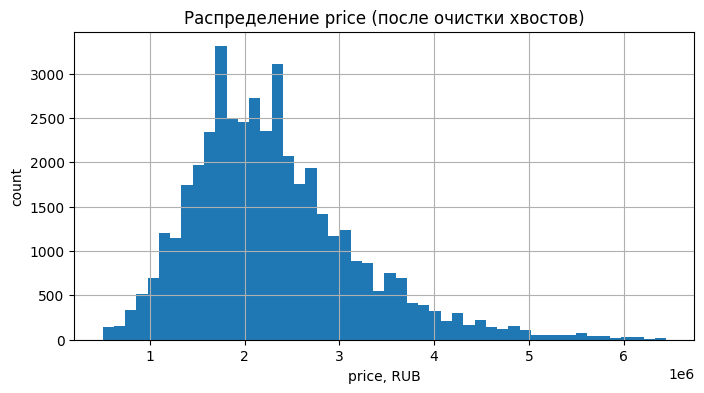

Skew: 1.029234671460034
Kurtosis: 1.647411905573319


In [15]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 4))
df['price'].hist(bins=50)
plt.title('Распределение price (после очистки хвостов)')
plt.xlabel('price, RUB')
plt.ylabel('count')
plt.show()
print('Skew:', df['price'].skew())
print('Kurtosis:', df['price'].kurtosis())

Вывод: распределение цены, как правило, не нормальное (правосторонняя асимметрия).

В ходе первичной обработки были оставлены данные только по выбранному региону, удалены дубликаты и некорректные записи, сформирован временной признак `year`, а столбцы `date` и `time` исключены. Дополнительно выполнено отсечение 1% хвостов распределений по целевой переменной и ряду значимых признаков, а также построены новые информативные признаки (логарифмы площадей, доля кухни, относительный этаж, индикаторы студии и первого/последнего этажа).

### **<font color='DarkOrange'> Задача 2. [1 балл]</font>**

Подготовка к обучению

1. Создайте матрицу объект-признак  `X` и вектор с целевой переменной (price) `y`.

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
# Целевая переменная
y = df['price'].copy()
# Признаки (исключаем price)
feature_cols = [
    'geo_lat', 'geo_lon',
    'building_type', 'object_type',
    'level', 'levels', 'rooms',
    'area', 'kitchen_area',
    'year',
    # добавляем новые признаки
    'log_area', 'log_kitchen_area',
    'kitchen_share', 'floor_ratio',
    'is_first_floor', 'is_last_floor'
    ]
missing = [c for c in feature_cols if c not in df.columns]
if missing:
    raise KeyError(f"В df отсутствуют колонки (проверь Задачу 1): {missing}")
for c in ['building_type', 'object_type']:
    df[c] = pd.to_numeric(df[c], errors='coerce')
df = df.dropna(subset=['building_type', 'object_type'])
X = df[feature_cols].copy()
X.shape, y.shape

((43052, 16), (43052,))


2. Разбейте данные на тренировочную и тестовую части, размер тестовой части — 30%.


In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42
)
X_train.shape, X_test.shape

((30136, 16), (12916, 16))

3. Для линейных моделей важно применить нормализацию, возьмем StandardScaler, обучим метод на тренировочных данных и применим его и к трейну, и к тесту.

In [18]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
X_train_scaled.shape, X_test_scaled.shape

((30136, 16), (12916, 16))

4. После масштабирования признаков `X_train` и `X_test` перестали быть объектами типа `pd.DataFrame`, это неудобно. Приведите их снова к `pd.DataFrame`.

In [19]:
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)
X_train_scaled.head()

,geo_lat,geo_lon,building_type,object_type,level,levels,rooms,area,kitchen_area,year,log_area,log_kitchen_area,kitchen_share,floor_ratio,is_first_floor,is_last_floor
762015,-0.273532,-0.438607,-1.367075,-0.395429,-0.267964,-0.018126,-0.946169,-1.301293,-0.513703,-1.641991,-1.534674,-0.498759,0.729643,-0.456329,-0.403582,-0.436934
4242358,-0.201813,-0.216963,-0.320214,2.528900,0.291311,-0.219252,-0.946169,-1.162593,0.113108,0.716759,-1.311455,0.284556,1.428027,0.599830,-0.403582,-0.436934
2513534,-0.283764,-0.464817,-1.367075,-0.395429,-0.827239,-0.018126,0.083766,-0.330395,-0.513703,-0.462616,-0.210023,-0.498759,-0.391759,-1.224445,-0.403582,-0.436934
2008881,3.833658,-2.069375,0.726647,-0.395429,-1.106876,-0.822629,0.083766,-0.330395,-0.827109,-0.462616,-0.210023,-0.967502,-0.723603,-1.301256,2.477810,-0.436934
5197473,0.120682,2.300676,0.726647,-0.395429,-1.106876,-1.426005,-0.946169,-1.169528,-0.952471,1.896134,-1.322281,-1.174053,-0.128647,-0.264300,2.477810,-0.436934


После применения StandardScaler признаки были приведены к нулевому среднему и единичному стандартному отклонению. Отрицательные и дробные значения являются ожидаемыми и отражают относительное отклонение объектов от среднего значения признака. Масштабирование необходимо для корректной работы линейных моделей и методов, основанных на расстояниях.

### **<font color='DarkOrange'> Задача 3. [1 балл]</font>**

Обучите на тренировочных данных с параметрами по умолчанию:

1) линейную регрессию Ridge;

<font color='OrangeRed'>**Важно!**</font> SVR может долго обучаться без нормализации данных, возьмите на заметку

In [20]:
from sklearn.linear_model import Ridge

ridge = Ridge(random_state=42)
ridge.fit(X_train_scaled, y_train)

Ridge(random_state=42)

2) метод опорных векторов [SVR](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVR.html) (с kernel='linear').

In [21]:
from sklearn.svm import SVR

svr = SVR(kernel='linear')
svr.fit(X_train_scaled, y_train)

SVR(kernel='linear')

3) С помощью обученных моделей сделайте предсказание на тестовых данных. Вычислите значение метрики [RMSE](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_squared_error.html) на тесте.

In [23]:
import numpy as np
from sklearn.metrics import mean_squared_error

y_pred_ridge = ridge.predict(X_test_scaled)
y_pred_svr = svr.predict(X_test_scaled)

rmse_ridge = np.sqrt(mean_squared_error(y_test, y_pred_ridge))
rmse_svr = np.sqrt(mean_squared_error(y_test, y_pred_svr))

print('RMSE Ridge:', rmse_ridge)
print('RMSE SVR (linear):', rmse_svr)

RMSE Ridge: 451346.89644153626
RMSE SVR (linear): 834114.712286424


### **<font color='DarkOrange'> Задача 4. [2 баллa]</font>**

Обучите [решающее дерево](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html#sklearn-tree-decisiontreeregressor) с параметрами по умолчанию на тренировочных данных, сделайте предсказание на тесте и вычислите на тесте RMSE

In [24]:
from sklearn.tree import DecisionTreeRegressor
import numpy as np
from sklearn.metrics import mean_squared_error

tree = DecisionTreeRegressor(random_state=42)
tree.fit(X_train, y_train)

y_pred_tree = tree.predict(X_test)
rmse_tree = np.sqrt(mean_squared_error(y_test, y_pred_tree))

print('RMSE DecisionTree (default, no scaling):', rmse_tree)

RMSE DecisionTree (default, no scaling): 416356.7308257329


Нужно ли масшабировать признаки для обучения решающего дерева? Проверьте это, заново разбив данные на тренировочную и тестовую части (назовите новые полученные объекты новыми названиями), и проведите обучение, предсказание и оценку метрики до масштабирования и после.

<font color='LightSteelBlue'>**Подсказка:**</font> Можно использовать любой метод мастшабирования признаков

In [25]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
import numpy as np
from sklearn.metrics import mean_squared_error

# разбиваем по новому
X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X, y, test_size=0.30, random_state=123
)

# дерево без масштабирования
tree2 = DecisionTreeRegressor(random_state=42)
tree2.fit(X_train2, y_train2)
pred_tree2 = tree2.predict(X_test2)
rmse_tree2 = np.sqrt(mean_squared_error(y_test2, pred_tree2))

# дерево после
scaler2 = StandardScaler()
X_train2_s = scaler2.fit_transform(X_train2)
X_test2_s = scaler2.transform(X_test2)

tree2_s = DecisionTreeRegressor(random_state=42)
tree2_s.fit(X_train2_s, y_train2)
pred_tree2_s = tree2_s.predict(X_test2_s)
rmse_tree2_s = np.sqrt(mean_squared_error(y_test2, pred_tree2_s))

print('RMSE Tree (no scaling):', rmse_tree2)
print('RMSE Tree (with scaling):', rmse_tree2_s)

RMSE Tree (no scaling): 410305.7563383377
RMSE Tree (with scaling): 408283.49354524526


Какой вывод про масштабирование признаков для обучения дерева можно сделать?

<font color='MediumOrchid'>**Ваши выводы тут:**</font>

Значения RMSE до и после масштабирования оказались почти одинаковыми. Что значит, что для решающего дерева масштабирование признаков не является обязательным, так как модель использует пороговые разбиения и не чувствительна к изменению масштаба признаков. Небольшие различия в метрике мы можем объяснить особенностями разбиения данных и процесса обучения.

### **<font color='DarkOrange'> Задача 5. [3 баллa]</font>**

Теперь ваша цель — максимально улучшить модели

Для этого:

1) у линейных моделей:
  * `SVR` (если смогли обучить модель) - подберите гиперпараметр `С` (переберите $20$ значений `C` в диапазоне от $0.1$ до $10$ с равным шагом);
  * `Ridge` - подберите гиперпараметр $\alpha$ (переберите $20$ значений $\alpha$ в диапазоне от $10^{-3}$ до $10^{3}$ с равным логарифмическим шагом)

2) у решающего дерева подберите `max_depth` (переберите глубину от $1$ до $10$ с шагом $1$) и `criterion` — `squared_error` или `absolute_error` (см. [документацию](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html#sklearn-tree-decisiontreeregressor)).

Для подбора параметров используйте [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html) с `5` фолдами и метрикой `r2`.

**<font color='OrangeRed'> Важно! </font>** Подбор параметров осуществляется только по тренировочным данным! Контролируйте свои пайплайны обучения на предмет ликов!

3) После подбора гиперпараметров обучите модели с найденными гиперпараметрами на тренировочных данных, сделайте предсказания на тесте и оцените их качество (`RMSE`).

In [26]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
import numpy as np
import pandas as pd

# Ridge
ridge_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', Ridge(random_state=42))
])
ridge_param_grid = {
    'model__alpha': np.logspace(-3, 3, 20)  # лог шаг
}
ridge_gs = GridSearchCV(
    ridge_pipe,
    ridge_param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)
ridge_gs.fit(X_train, y_train)

# SVR
svr_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', SVR(kernel='linear'))
])
svr_param_grid = {
    'model__C': np.linspace(0.1, 10.0, 20) # равномерный шаг
}
svr_gs = GridSearchCV(
    svr_pipe,
    svr_param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)
svr_gs.fit(X_train, y_train)

# дерево решений
tree = DecisionTreeRegressor(random_state=42)
tree_param_grid = {
    'max_depth': list(range(1, 11)),
    'criterion': ['squared_error', 'absolute_error']
}
tree_gs = GridSearchCV(
    tree,
    tree_param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)
tree_gs.fit(X_train, y_train)

print('Best Ridge params:', ridge_gs.best_params_)
print('Best SVR params:', svr_gs.best_params_)
print('Best Tree params:', tree_gs.best_params_)

# RMSE на тестовой выборке
best_ridge = ridge_gs.best_estimator_
best_svr = svr_gs.best_estimator_
best_tree = tree_gs.best_estimator_

pred_ridge = best_ridge.predict(X_test)
pred_svr = best_svr.predict(X_test)
pred_tree = best_tree.predict(X_test)

rmse_best_ridge = np.sqrt(mean_squared_error(y_test, pred_ridge))
rmse_best_svr = np.sqrt(mean_squared_error(y_test, pred_svr))
rmse_best_tree = np.sqrt(mean_squared_error(y_test, pred_tree))

results = pd.DataFrame({
    'model': ['Ridge (tuned)', 'SVR linear (tuned)', 'DecisionTree (tuned)'],
    'RMSE': [rmse_best_ridge, rmse_best_svr, rmse_best_tree]
}).sort_values('RMSE')

results

Best Ridge params: {'model__alpha': np.float64(1.438449888287663)}
Best SVR params: {'model__C': np.float64(10.0)}
Best Tree params: {'criterion': 'squared_error', 'max_depth': 10}


,model,RMSE
2,DecisionTree (tuned),377895.324067
0,Ridge (tuned),451345.848123
1,SVR linear (tuned),586069.151035


Какая модель справилась с решением задачи лучше всего по метрике RMSE?

<font color='LightSteelBlue'>**Подсказка:**</font> Оформите полученные метрики в `pd.DataFrame`

In [27]:
results.reset_index(drop=True)

,model,RMSE
0,DecisionTree (tuned),377895.324067
1,Ridge (tuned),451345.848123
2,SVR linear (tuned),586069.151035


<font color='MediumOrchid'>**Ваши выводы тут:**</font>

Мы перебрали параметры для Ridge, SVR и дерева с помощью GridSearchCV (используя 5 фолдов, и метрику r2), после чего пересчитали RMSE на тестовой выборке. Модель с наименьшим RMSE считаем лучшей, что и видно в табличке. Остальные модели показали более высокий RMSE, значит в этой задаче они предсказывают цену хуже.

### **<font color='DarkOrange'> Задача 6. [1 балл]</font>**

Постройте диаграммы (горизонтальные бары) важности признаков для линейной регрессии и дерева (для линейных моделей берите модуль значений весов). Сравните между собой списки из трёх самых важных признаков. Совпадают ли они?

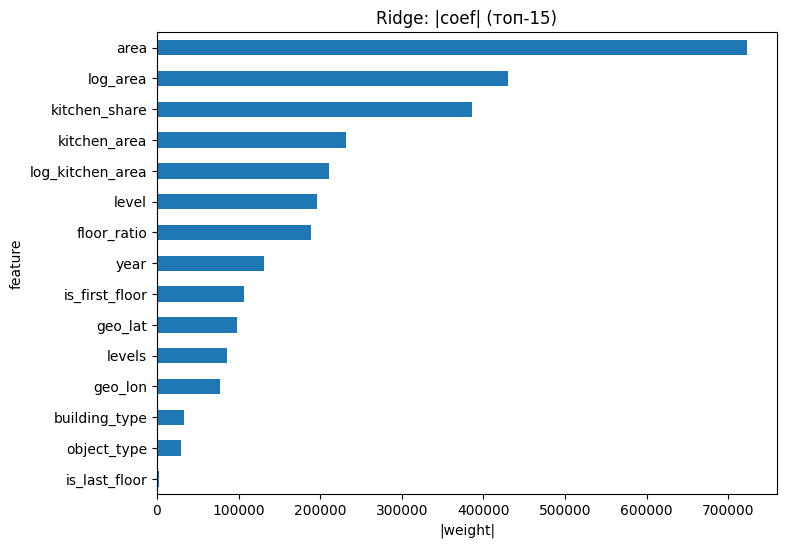

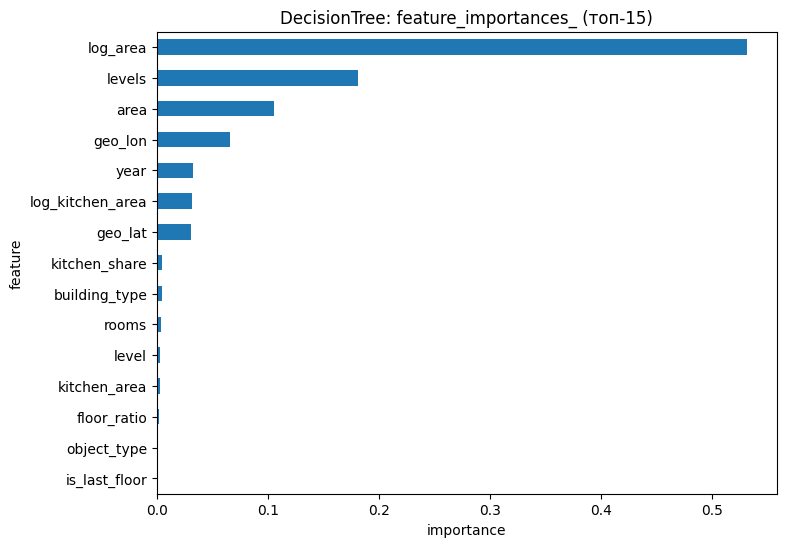

Top-3 Ridge: ['area', 'log_area', 'kitchen_share']
Top-3 Tree: ['log_area', 'levels', 'area']
Совпадают ли топ-3 полностью? False


In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# из 5 задачи берём лучшие модельки Pipeline(StandardScaler + Ridge) и DecisionTreeRegressor

# Ridge у которого акцент на коэффициентах
ridge_model = best_ridge.named_steps['model']
ridge_importance = pd.Series(np.abs(ridge_model.coef_), index=X_train.columns).sort_values(ascending=True)

plt.figure(figsize=(8, 6))
ridge_importance.tail(15).plot(kind='barh')
plt.title('Ridge топ')
plt.xlabel('|weight|')
plt.ylabel('feature')
plt.show()

# дерево решений, где акцентируем внимание на деталях
tree_importance = pd.Series(best_tree.feature_importances_, index=X_train.columns).sort_values(ascending=True)

plt.figure(figsize=(8, 6))
tree_importance.tail(15).plot(kind='barh')
plt.title('Дерево решений топ')
plt.xlabel('importance')
plt.ylabel('feature')
plt.show()

# Топ признаков
top_ridge = list(ridge_importance.sort_values(ascending=False).head(3).index)
top_tree = list(tree_importance.sort_values(ascending=False).head(3).index)

print('Top Ridge:', top_ridge)
print('Top Tree:', top_tree)
print('Совпадает ли топ полностью?', set(top_ridge) == set(top_tree))

<font color='MediumOrchid'>**Ваши выводы тут:**</font>

Из диаграмм мы видим, что на цену квартиры больше всего влияет площадь. Обе модели выделяют area и log_area как наиболее влиятельные признаки. Остальные признаки в топе различаются, что можно объяснить разным принципом работы моделей, а именно, Ridge учитывает линейное влияние, а решающее дерево роль признаков при разбиениях. По итогу результаты похожи на то что мы от них ожидаем.

### **<font color='DarkOrange'> Задача 7. [1 балл]</font>**

Сделайте выводы по самой лучшей модели:

1. Какая модель после подбора гиперпараметров лучше всего решает задачу с точки зрения метрики RMSE?

2. Достаточное ли качество получившейся модели? Можно ли ее использовать в проде?

3. Как можно еще улучшить получившуюся модель? Как в случае линейной модели, так и для дерева.

<font color='MediumOrchid'>**Ваши выводы тут:**</font>


1) Как по нашему мнению лучшей моделью по RMSE оказалось решающее дерево после подбора параметров, как минимум по таблице лучшей она считается из-за минимального RMSE. Также оно даёт наименьшую ошибку по сравнению с Ridge и SVR.

2) По одной метрике RMSE говорить что модель готова решать серьёзные задачи нельзя. Ошибки могут возникать в разных местах, например по ценнику или типу зданий и тд. Для прод использования нужно дополнительно проверить качество на разных подгруппах и посмотреть устойчивость по времени и на других более сложных датасетах и сценариях.

3)

   - Можно попробовать по другому обрабатывать категории типа здания и тд, так как сейчас они как числа, а по смыслу это именно категории, поэтому лучше сделать отдельные типы или галочки для каждого значения (из примеров one-hot), чтобы модель не думала, что какой нибудь кирпич лучше, чем панелька.
   - Для дерева можно было бы добавить защиту от переобучения попробовал параметры по типу min_leaf и min_split (чтобы дерево не делало слишком мелкие разбиения).
  - Можно добавить простые признаки, например, цена за квадрат (price/area) хотя бы для анализа выбросов, чтобы посмотреть как сильно она может различаться и скакать.